# BER vs. Distance: PNN, Conventional CDC, and Joint CDC

This notebook compares seven strategies over linear fiber links from 50 to 1000 km in 50 km increments. Chromatic dispersion is the only propagation effect; Kerr is disabled. Correlated transmitter (TX) and local-oscillator (LO) phase noise is retained, with linewidths of 0 Hz, 100 kHz, and 1 MHz.

Before training, the notebook numerically verifies the sign convention used by the main propagator, conventional CDC, and joint CDC. Each curve point uses a PNN trained specifically for that distance and linewidth. Training and test sets are separate. For joint-training cases, PNN weights are optimized using BER measured after the corresponding DSP algorithm.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'src').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.dsp.transmitter import (
    ElectricalFilterParams, IQMZMParams, generate_qpsk_symbols, modulate_optical_signal
)
from src.dsp.fiber import FiberParams, fibra_monomodo
from src.dsp.noise_models import generate_correlated_phases
from src.dsp.receiver import coherent_detection, cd_compensation, sample_to_symbols, demap_qpsk
from src.utils.metrics import calculate_ber
from src.dsp.edfa import EDFAIdeal
from src.models.pnn import PhotonicNeuralNetwork
from src.dsp.joint_pnn_cdc_equalizer import (
    cd_compensation_joint_pnn, cd_compensation_traditional, simulate_fiber_dispersion
)
from scripts.optimize_pnn_pso import particle_swarm_optimize


## 1. System and Training Parameters

The optical parameters follow the earlier notebooks. PSO settings are reduced by default for an exploratory run; increase the population and iteration count before interpreting final results. Computation grows quickly because each distance/linewidth point requires three PNN trainings: without CDC, with conventional CDC, and with joint CDC.

In [2]:
# Link and modulation
NUM_SYMBOLS_TRAIN = 2**9
NUM_SYMBOLS_TEST = 2**12
SPS = 8
SYMBOL_RATE = 10e9
WAVELENGTH = 1550e-9
SPAN_LENGTH_KM = 50.0
DISTANCES_KM = np.arange(50.0, 1000.0 + SPAN_LENGTH_KM, SPAN_LENGTH_KM)
LINEWIDTHS_HZ = np.array([0.0, 100e3, 1e6])
PHASE_CORRELATION_TX_RX = 0.99

FIBER_PARAMS = FiberParams(alpha_db=0.2, d_1550=16.0, slope_s=0.09, n2=3.2e-20, a_eff=70e-12)
IQ_PARAMS = IQMZMParams(electrical_response=False)
FILTER_PARAMS = ElectricalFilterParams(tipo='cosseno_levantado', largura_banda_hz=2*SYMBOL_RATE, ordem=7)
MODULATOR = 'iq_mzm'

# PNN and PSO (settings for final convergence studies)
PNN_NUM_CHANNELS = 32
PNN_BASE_DELAY_PS = 20.0
PNN_NORMALIZE_POWER = True
PNN_TRAIN_SEED = 20261101
PSO_SWARM_SIZE = 60
PSO_ITERATIONS = 100

# PNN-response inversion: ε relative to mean |H_PNN|².
JOINT_CDC_REG_REL = 1e-3

RX_EDFA_GAIN_DB = 20.0
RX_TARGET_DBM = 0.0
TX_POWER_DBM = 0.0
PHASE_SEED_TEST = 1000
PHASE_SEED_TRAIN = 20262101

PLOT_FLOOR = 1.0 / (2 * NUM_SYMBOLS_TEST)
ARTIFACT_DIR = PROJECT_ROOT / 'artifacts' / 'figures'
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

assert np.allclose(np.diff(DISTANCES_KM), SPAN_LENGTH_KM)
assert np.isclose(DISTANCES_KM[-1], 1000.0)
print(f'{len(DISTANCES_KM)} distances; linewidths: {LINEWIDTHS_HZ} Hz')
print(f'Exploratory PSO: {PSO_SWARM_SIZE} particles × {PSO_ITERATIONS} iterations')


20 distances; linewidths: [      0.  100000. 1000000.] Hz
Exploratory PSO: 60 particles × 100 iterations


## 2. Link, Receiver, and Measurement Functions

Each 50 km span is followed by an ideal EDFA that compensates its loss. The terminal stage sets received power to 0 dBm, as in earlier notebooks, so the distance axis mainly highlights accumulated dispersion and phase noise. Propagation uses `regime=0`, with Kerr disabled.

In [3]:
SAMPLE_RATE = SPS * SYMBOL_RATE
DT = 1.0 / SAMPLE_RATE
EDFA_MODEL = EDFAIdeal
RX_EDFA_GAIN_DB = 20.0

def mean_power_dbm(field):
    return 10.0 * np.log10(np.mean(np.abs(field)**2) / 1e-3)

def propagate_linear_spans(field, t, distance_km):
    n_spans = int(round(distance_km / SPAN_LENGTH_KM))
    if n_spans < 1 or not np.isclose(n_spans * SPAN_LENGTH_KM, distance_km):
        raise ValueError('Distance must be a positive multiple of 50 km.')
    inline_edfa = EDFA_MODEL(gain_db=FIBER_PARAMS.alpha_db * SPAN_LENGTH_KM)
    out = np.asarray(field, dtype=complex).copy()
    for _ in range(n_spans):
        out, _, _ = fibra_monomodo(
            t, out, wavelength=WAVELENGTH, t0=1.0/SYMBOL_RATE,
            length_km=SPAN_LENGTH_KM, regime=0, params=FIBER_PARAMS, num_steps=5
        )
        out = inline_edfa.amplify(out)
    return out

def set_receiver_power(field):
    amplified = EDFA_MODEL(gain_db=RX_EDFA_GAIN_DB).amplify(field)
    attenuation_db = mean_power_dbm(amplified) - RX_TARGET_DBM
    if attenuation_db < -1e-9:
        raise ValueError('Increase the terminal EDFA gain to reach the target power.')
    return amplified * 10.0**(-max(attenuation_db, 0.0)/20.0)

def ber_from_field(field, phase_lo, bits, sps=SPS):
    bb = coherent_detection(field, phase_lo=phase_lo)
    symbols_rx = sample_to_symbols(bb, sps=sps)
    bits_rx = demap_qpsk(symbols_rx)
    n = min(len(bits), len(bits_rx))
    return calculate_ber(bits[:n], bits_rx[:n])

def optimize_pnn(field_train, phase_lo_train, train_bits, distance_km, objective_mode, seed):
    model = PhotonicNeuralNetwork(
        num_channels=PNN_NUM_CHANNELS, base_delay_ps=PNN_BASE_DELAY_PS,
        normalize_power=PNN_NORMALIZE_POWER, responsivity=1.0
    )
    bounds = [(0.0, 1.0)]*PNN_NUM_CHANNELS + [(-np.pi, np.pi)]*PNN_NUM_CHANNELS
    def objective(position):
        model.set_weights(position[:PNN_NUM_CHANNELS], position[PNN_NUM_CHANNELS:])
        _, field_pnn = model.forward(field_train, dt_s=DT, return_optical_field=True)
        bb = coherent_detection(field_pnn, phase_lo=phase_lo_train)
        if objective_mode == 'cdc':
            bb = cd_compensation(bb, DT, distance_km, dispersion_d=FIBER_PARAMS.d_1550)
        elif objective_mode == 'joint_cdc':
            h = model.frequency_response(np.fft.fftfreq(len(bb), d=DT))
            eps = JOINT_CDC_REG_REL * np.mean(np.abs(h)**2)
            bb = cd_compensation_joint_pnn(
                bb, DT, distance_km, model, dispersion_d=FIBER_PARAMS.d_1550,
                wavelength=WAVELENGTH, reg_factor=eps
            )
        elif objective_mode != 'none':
            raise ValueError(f'Invalid objective: {objective_mode}')
        bits_rx = demap_qpsk(sample_to_symbols(bb, sps=SPS))
        n = min(len(train_bits), len(bits_rx))
        return calculate_ber(train_bits[:n], bits_rx[:n])
    result = particle_swarm_optimize(
        objective, bounds, swarm_size=PSO_SWARM_SIZE, max_iterations=PSO_ITERATIONS,
        periodic_dimensions=range(PNN_NUM_CHANNELS, 2*PNN_NUM_CHANNELS), seed=seed
    )
    return result


## 3. Audit of the CDC Sign Convention

This check isolates the discrepancy before PSO: it uses a complex impulse and linear fiber without attenuation, Kerr, or noise. First, it compares the main propagator (`fibra_monomodo`, `regime=0`) with the dispersion helper in the joint CDC module. It then checks that conventional CDC and joint CDC undo this propagation. The test PNN has only its first tap active, preventing delays or spectral notches from affecting the diagnosis.

The relative errors below should be close to numerical precision. If the helper propagator or joint CDC error is large, do not interpret trained curves until the inconsistency is fixed. This cell does not use the span/EDFA propagation from the sweep; it is a controlled test of signs and filters.

In [4]:
N_DIAG = 2**12
t_diag = np.arange(N_DIAG)*DT
impulse = np.zeros(N_DIAG, dtype=complex)
impulse[0] = 1.0

# alpha=0 removes attenuation only, isolating the filter phases.
fiber_diag_params = FiberParams(
    alpha_db=0.0, d_1550=FIBER_PARAMS.d_1550, slope_s=FIBER_PARAMS.slope_s,
    n2=FIBER_PARAMS.n2, a_eff=FIBER_PARAMS.a_eff, c=FIBER_PARAMS.c
)

def rel_error(reference, estimate):
    return float(np.linalg.norm(reference-estimate)/(np.linalg.norm(reference)+1e-30))

diag_rows = []
diag_length_km = 1000.0
fiber_main, _, _ = fibra_monomodo(
    t_diag, impulse, wavelength=WAVELENGTH, t0=1.0/SYMBOL_RATE,
    length_km=diag_length_km, regime=0, params=fiber_diag_params, num_steps=1
)
fiber_aux = simulate_fiber_dispersion(
    impulse, DT, diag_length_km, dispersion_d=fiber_diag_params.d_1550,
    wavelength=WAVELENGTH, c=fiber_diag_params.c
)
cdc_rx = cd_compensation(
    fiber_main, DT, diag_length_km, dispersion_d=fiber_diag_params.d_1550,
    wavelength=WAVELENGTH, c=fiber_diag_params.c
)
cdc_module = cd_compensation_traditional(
    fiber_main, DT, diag_length_km, dispersion_d=fiber_diag_params.d_1550,
    wavelength=WAVELENGTH, c=fiber_diag_params.c
)
diag_rows.append(('Auxiliary propagator vs. fiber.py', rel_error(fiber_main, fiber_aux)))
diag_rows.append(('fiber.py + receiver CDC vs. TX', rel_error(impulse, cdc_rx)))
diag_rows.append(('joint-module CDC vs. receiver CDC', rel_error(cdc_rx, cdc_module)))

# PNN de passagem escalada: apenas tap 0 ativo; H_PNN = 1/N.
pnn_diag = PhotonicNeuralNetwork(
    num_channels=PNN_NUM_CHANNELS, base_delay_ps=PNN_BASE_DELAY_PS,
    amplitude_weights=np.r_[1.0, np.zeros(PNN_NUM_CHANNELS-1)],
    phase_weights=np.zeros(PNN_NUM_CHANNELS), normalize_power=True
)
_, field_after_pnn = pnn_diag.forward(fiber_main, DT, return_optical_field=True)
traditional_after_pnn = cd_compensation(
    field_after_pnn, DT, diag_length_km, dispersion_d=fiber_diag_params.d_1550,
    wavelength=WAVELENGTH, c=fiber_diag_params.c
)
joint_after_pnn = cd_compensation_joint_pnn(
    field_after_pnn, DT, diag_length_km, pnn_diag,
    dispersion_d=fiber_diag_params.d_1550, wavelength=WAVELENGTH,
    c=fiber_diag_params.c, reg_factor=1e-12
)
expected_traditional = impulse/PNN_NUM_CHANNELS
diag_rows.append(('Fiber + identity PNN + conventional CDC vs. TX/N', rel_error(expected_traditional, traditional_after_pnn)))
diag_rows.append(('Fiber + identity PNN + joint CDC vs. TX', rel_error(impulse, joint_after_pnn)))

display(pd.DataFrame(diag_rows, columns=['Controlled check (1000 km)', 'Relative error']))


,Controlled check (1000 km),Relative error
0,Auxiliary propagator vs. fiber.py,0.000000e+00
1,fiber.py + receiver CDC vs. TX,4.448111e-16
2,joint-module CDC vs. receiver CDC,0.000000e+00
3,Fiber + identity PNN + conventional CDC vs. TX/N,4.448111e-16
4,Fiber + identity PNN + joint CDC vs. TX,1.024000e-09


## 4. Training and Test Frames, and Phase Noise

Training and test symbols are distinct. For each linewidth, TX and LO have correlated phase noise with \(\rho=0.99\), using one realization for training and an independent realization for testing. The same test realizations are reused at all distances for each linewidth, allowing curve comparisons without changing the data sequence or noise between points.

In [5]:
train_symbols, train_bits = generate_qpsk_symbols(NUM_SYMBOLS_TRAIN, seed=PNN_TRAIN_SEED)
test_symbols, test_bits = generate_qpsk_symbols(NUM_SYMBOLS_TEST, seed=PNN_TRAIN_SEED + 1)

train_tx_0dbm, t_train, dt_train = modulate_optical_signal(
    train_symbols, sps=SPS, launch_power_dbm=0.0, symbol_rate=SYMBOL_RATE,
    modulator=MODULATOR, iq_params=IQ_PARAMS, filter_params=FILTER_PARAMS,
    plot_filter=False, n_plot=0
)
test_tx_0dbm, t_test, dt_test = modulate_optical_signal(
    test_symbols, sps=SPS, launch_power_dbm=0.0, symbol_rate=SYMBOL_RATE,
    modulator=MODULATOR, iq_params=IQ_PARAMS, filter_params=FILTER_PARAMS,
    plot_filter=False, n_plot=0
)
if not np.isclose(dt_train, dt_test):
    raise ValueError('Training and test must use the same sampling period.')
DT = dt_test

phase_sets = {}
for linewidth_index, linewidth_hz in enumerate(LINEWIDTHS_HZ):
    phase_sets[float(linewidth_hz)] = {
        'train': generate_correlated_phases(
            len(t_train), DT, float(linewidth_hz), PHASE_CORRELATION_TX_RX,
            seed=PHASE_SEED_TRAIN + linewidth_index
        ),
        'test': generate_correlated_phases(
            len(t_test), DT, float(linewidth_hz), PHASE_CORRELATION_TX_RX,
            seed=PHASE_SEED_TEST + linewidth_index
        ),
    }
print(f'Training: {NUM_SYMBOLS_TRAIN} symbols; test: {NUM_SYMBOLS_TEST} symbols; SPS={SPS}')


Training: 512 symbols; test: 4096 symbols; SPS=8


## 5. Training and Evaluation at Each Distance

For each (distance, linewidth) pair, three independent PNNs are trained: (A) minimizes BER without CDC; (B) minimizes BER after conventional CDC; and (C) minimizes BER after joint CDC.

PNN A supplies the **PNN only**, **PNN + CDC with separate training**, and **PNN + joint CDC with separate training** curves: it is trained without CDC, frozen, and then evaluated with each DSP. PNNs B and C produce **PNN + CDC with joint training** and **PNN + joint CDC with joint training**, respectively. The DSP equalizers are deterministic and have no trainable weights; “joint training” means that PNN weights are optimized using BER after the PNN+DSP chain.

The no-PNN baselines (no compensation and CDC only) are computed once per distance/linewidth pair. This is the most computationally intensive cell.

In [6]:
CURVE_NAMES = [
    'sem compensação', 'CDC apenas', 'PNN apenas',
    'PNN + CDC treino separado', 'PNN + CDC treino conjunto',
    'PNN + joint CDC treino separado', 'PNN + joint CDC treino conjunto',
]
CURVE_DISPLAY_NAMES = ['No compensation', 'CDC only', 'PNN only', 'PNN + CDC (separate training)', 'PNN + CDC (joint training)', 'PNN + joint CDC (separate training)', 'PNN + joint CDC (joint training)']
ber_curves = {float(lw): {name: [] for name in CURVE_NAMES} for lw in LINEWIDTHS_HZ}
training_records = {}

for linewidth_index, linewidth_hz in enumerate(LINEWIDTHS_HZ):
    key = float(linewidth_hz)
    phase_tx_train, phase_lo_train = phase_sets[key]['train']
    phase_tx_test, phase_lo_test = phase_sets[key]['test']
    for distance_index, distance_km in enumerate(DISTANCES_KM):
        tx_train = train_tx_0dbm * np.exp(1j*phase_tx_train)
        tx_test = test_tx_0dbm * np.exp(1j*phase_tx_test)
        field_train = set_receiver_power(propagate_linear_spans(tx_train, t_train, distance_km))
        field_test = set_receiver_power(propagate_linear_spans(tx_test, t_test, distance_km))

        # No-PNN baselines. Conventional CDC uses the actual physical distance.
        bb_test = coherent_detection(field_test, phase_lo=phase_lo_test)
        ber_curves[key]['sem compensação'].append(
            calculate_ber(test_bits, demap_qpsk(sample_to_symbols(bb_test, SPS)))
        )
        bb_cdc = cd_compensation(bb_test, DT, distance_km, dispersion_d=FIBER_PARAMS.d_1550)
        ber_curves[key]['CDC apenas'].append(
            calculate_ber(test_bits, demap_qpsk(sample_to_symbols(bb_cdc, SPS)))
        )

        # A: train without DSP; B: train with conventional CDC; C: train with joint CDC.
        seed_base = PNN_TRAIN_SEED + 10000*distance_index + 100*linewidth_index
        pso_none = optimize_pnn(field_train, phase_lo_train, train_bits, distance_km, 'none', seed_base)
        pso_cdc = optimize_pnn(field_train, phase_lo_train, train_bits, distance_km, 'cdc', seed_base + 1)
        pso_joint = optimize_pnn(field_train, phase_lo_train, train_bits, distance_km, 'joint_cdc', seed_base + 2)
        training_records[(float(distance_km), key)] = {
            'pnn_only': pso_none, 'pnn_cdc_joint_training': pso_cdc,
            'pnn_joint_cdc_joint_training': pso_joint,
        }

        model = PhotonicNeuralNetwork(
            num_channels=PNN_NUM_CHANNELS, base_delay_ps=PNN_BASE_DELAY_PS,
            normalize_power=PNN_NORMALIZE_POWER
        )
        def evaluate_weights(pso_result, dsp):
            model.set_weights(pso_result['amplitude_weights'], pso_result['phase_weights'])
            _, field_out = model.forward(field_test, dt_s=DT, return_optical_field=True)
            bb = coherent_detection(field_out, phase_lo=phase_lo_test)
            if dsp == 'cdc':
                bb = cd_compensation(bb, DT, distance_km, dispersion_d=FIBER_PARAMS.d_1550)
            elif dsp == 'joint_cdc':
                h = model.frequency_response(np.fft.fftfreq(len(bb), d=DT))
                eps = JOINT_CDC_REG_REL*np.mean(np.abs(h)**2)
                bb = cd_compensation_joint_pnn(
                    bb, DT, distance_km, model, dispersion_d=FIBER_PARAMS.d_1550,
                    wavelength=WAVELENGTH, reg_factor=eps
                )
            return calculate_ber(test_bits, demap_qpsk(sample_to_symbols(bb, SPS)))

        ber_curves[key]['PNN apenas'].append(evaluate_weights(pso_none, 'none'))
        ber_curves[key]['PNN + CDC treino separado'].append(evaluate_weights(pso_none, 'cdc'))
        ber_curves[key]['PNN + CDC treino conjunto'].append(evaluate_weights(pso_cdc, 'cdc'))
        ber_curves[key]['PNN + joint CDC treino separado'].append(evaluate_weights(pso_none, 'joint_cdc'))
        ber_curves[key]['PNN + joint CDC treino conjunto'].append(evaluate_weights(pso_joint, 'joint_cdc'))

        print(f'{linewidth_hz/1e3:g} kHz | {distance_km:4.0f} km | BERs calculadas')


0 kHz |   50 km | BERs calculadas
0 kHz |  100 km | BERs calculadas
0 kHz |  150 km | BERs calculadas
0 kHz |  200 km | BERs calculadas
0 kHz |  250 km | BERs calculadas
0 kHz |  300 km | BERs calculadas
0 kHz |  350 km | BERs calculadas
0 kHz |  400 km | BERs calculadas
0 kHz |  450 km | BERs calculadas
0 kHz |  500 km | BERs calculadas
0 kHz |  550 km | BERs calculadas
0 kHz |  600 km | BERs calculadas
0 kHz |  650 km | BERs calculadas
0 kHz |  700 km | BERs calculadas
0 kHz |  750 km | BERs calculadas
0 kHz |  800 km | BERs calculadas
0 kHz |  850 km | BERs calculadas
0 kHz |  900 km | BERs calculadas
0 kHz |  950 km | BERs calculadas
0 kHz | 1000 km | BERs calculadas
100 kHz |   50 km | BERs calculadas
100 kHz |  100 km | BERs calculadas
100 kHz |  150 km | BERs calculadas
100 kHz |  200 km | BERs calculadas
100 kHz |  250 km | BERs calculadas
100 kHz |  300 km | BERs calculadas
100 kHz |  350 km | BERs calculadas
100 kHz |  400 km | BERs calculadas
100 kHz |  450 km | BERs calcula

## 6. BER Curves vs. Distance

Each panel uses one linewidth and shows the same seven conditions. Zero BER values are placed at the plot floor only so they appear on the logarithmic scale; stored data retain measured values, including zeros.

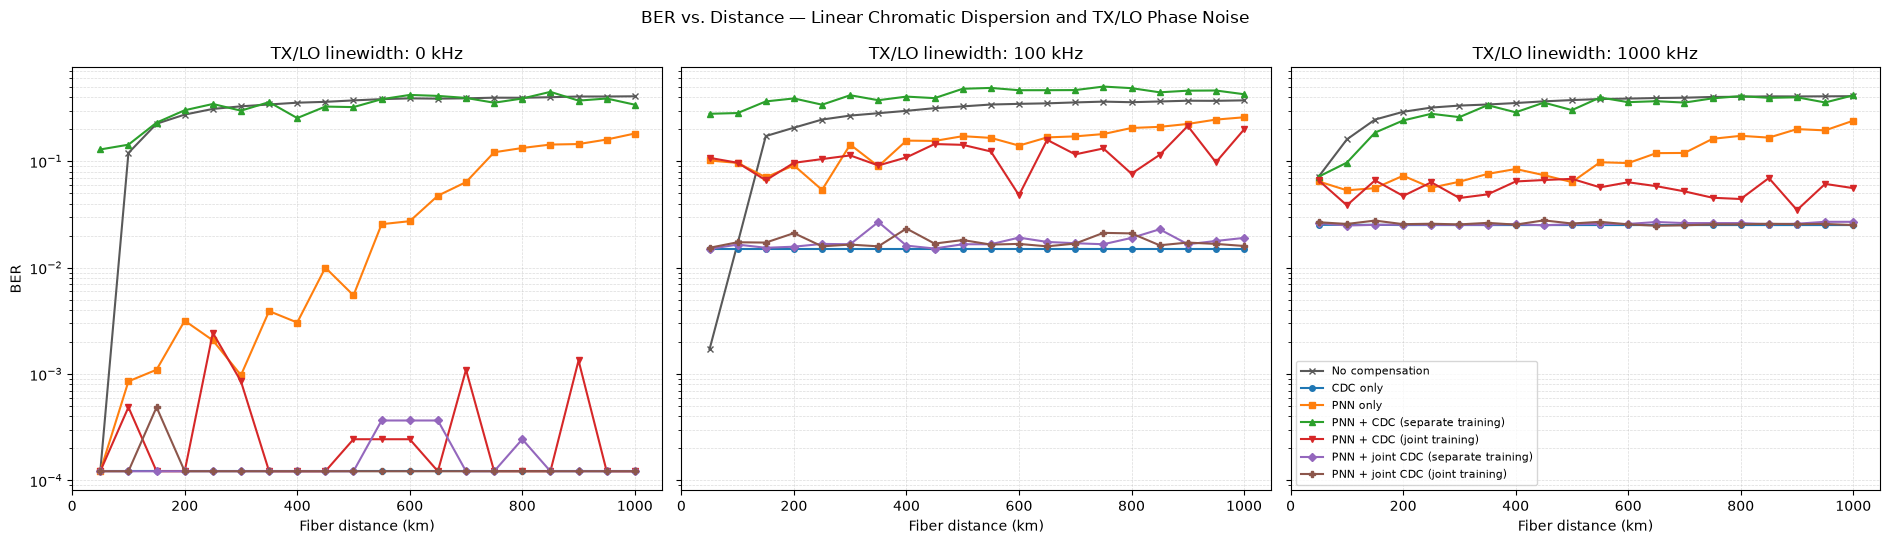

Figure saved to: D:\gits\PHOTONICS_2026\Codigos\python\pnn_coerente\artifacts\figures\ber_distancia_pnn_cdc_joint_cdc_tres_larguras_linha.png


In [7]:
colors = ['0.35', 'tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown']
markers = ['x', 'o', 's', '^', 'v', 'D', 'P']
fig, axes = plt.subplots(1, len(LINEWIDTHS_HZ), figsize=(19, 5.5), sharey=True)
for ax, linewidth_hz in zip(axes, LINEWIDTHS_HZ):
    key = float(linewidth_hz)
    for curve_index, (name, color, marker) in enumerate(zip(CURVE_NAMES, colors, markers)):
        vals = np.asarray(ber_curves[key][name], dtype=float)
        ax.semilogy(DISTANCES_KM, np.maximum(vals, PLOT_FLOOR), marker=marker,
                    linewidth=1.5, markersize=4, color=color, label=CURVE_DISPLAY_NAMES[curve_index])
    ax.set_title(f'TX/LO linewidth: {linewidth_hz/1e3:g} kHz')
    ax.set_xlabel('Fiber distance (km)')
    ax.set_xticks(np.arange(0, 1001, 200))
    ax.grid(True, which='both', linestyle='--', alpha=0.45)
axes[0].set_ylabel('BER')
axes[-1].legend(fontsize=8, loc='best')
fig.suptitle('BER vs. Distance — Linear Chromatic Dispersion and TX/LO Phase Noise')
fig.tight_layout()
output_path = ARTIFACT_DIR / 'ber_distancia_pnn_cdc_joint_cdc_tres_larguras_linha.png'
fig.savefig(output_path, dpi=250, bbox_inches='tight')
plt.show()
print(f'Figure saved to: {output_path}')


## 7. Scenario Definitions and Comparison Limits

- **No compensation:** fiber field received by the coherent detector, without CDC.
- **CDC only:** no PNN; conventional DSP compensates dispersion using the actual link distance.
- **PNN only:** PNN trained without DSP and evaluated without CDC.
- **PNN + CDC, separate training:** the same PNN trained without DSP is evaluated with conventional CDC.
- **PNN + CDC, joint training:** PNN trained to minimize BER after conventional CDC.
- **PNN + joint CDC, separate training:** the PNN trained without DSP is evaluated with the new equalizer that also uses \(H_{\mathrm{PNN}}(f)\).
- **PNN + joint CDC, joint training:** PNN trained to minimize BER after joint CDC; the equalizer is recomputed with candidate weights at each PSO evaluation.

Weights are specialized for each distance and linewidth, so the curves do not represent one fixed PNN over the entire link. There are three PSO trainings per distance/linewidth point. For robust conclusions, increase the population and iteration count, repeat with multiple seeds, and compare convergence histories. Joint CDC regularization is fixed relative to the mean of \(|H_{\mathrm{PNN}}|^2\); sweeping \(\varepsilon\) may change the curves.

The repository PNN is applied to the optical field before coherent detection; its square-law current is not used as input to the complex equalizer. The joint response assumes a linear field model and does not compensate TX/LO phase noise. BER includes residual phase noise but excludes ASE/AWGN, timing error, frequency error, and Kerr effects.